Samajhna pehle: Ensemble matlab bahut saare chhote models ko milakar ek bada model banana. Dono ka tareeka alag hai:

1. Random Forest (bagging): kai gehre trees, har ek data ke alag random sample par. Phir sabka average. Isse overfitting kam hoti hai (variance girta hai).
2. XGBoost (boosting): chhote, shallow trees ek ke baad ek. Har naya tree pichhle ki galtiyan sudharta hai. Yeh zyada taakatwar hai, lekin zyada hyperparameters hain aur zyada rounds par overfit kar sakta hai.

Dono ko scaling nahi chahiye (Day 64). Aur ye Day 69 ke akele tree se zyada stable hote hain.

Aaj ke rules:

1. Training aur comparison sirf X_train_v2.csv par, Day 70 jaise same CV folds par. Test set band rahega.
2. Imbalance handling teeno models mein ek jaisi (class weights), warna comparison fair nahi hoga.
3. Aaj tuning nahi hai. Wo kal (Day 84) hai. Aaj sensible defaults se sirf ye dekhna hai ki ensembles ka faida aata hai ya nahi.

1. src/models/cv_compare.py (Day 85 ke comparison report mein bhi kaam aayega):

In [1]:
"""Same-folds CV comparison helper."""
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import cross_validate

SCORING = ['roc_auc', 'average_precision', 'f1', 'recall', 'precision']


def cv_compare(models: dict, X, y, cv, scoring=SCORING):
    """Har model ko wahi folds par chalao. (summary table, fold-wise AUC) return karta hai."""
    rows, folds = [], {}
    for name, model in models.items():
        res = cross_validate(clone(model), X, y, cv=cv, scoring=scoring,
                             return_train_score=True, n_jobs=1)   # models khud n_jobs=-1 use karte hain
        row = {'model': name}
        row.update({m: res[f'test_{m}'].mean() for m in scoring})
        row['auc_std'] = res['test_roc_auc'].std()
        row['train_auc'] = res['train_roc_auc'].mean()
        row['fit_sec'] = res['fit_time'].mean()
        rows.append(row)
        folds[name] = res['test_roc_auc']
    return pd.DataFrame(rows).set_index('model'), pd.DataFrame(folds)

2. Setup:

In [4]:
import sys
import os
sys.path.append(os.path.abspath("../../"))
import warnings; warnings.filterwarnings('ignore')
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

from src.features.build_features import NUM_V2
from src.models.cv_compare import cv_compare

X_tr = pd.read_csv('../../data/processed/X_train_v2.csv').astype(float)   # bool dummies ko float banao
y_tr = pd.read_csv('../../data/processed/y_train.csv').squeeze()
assert len(X_tr) == len(y_tr)
print(X_tr.shape, "| churn rate:", round(y_tr.mean(), 3), "| xgboost", xgboost.__version__)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)    # Day 64B/70 wale hi folds
pos_weight = (y_tr == 0).sum() / (y_tr == 1).sum()                 # XGBoost ka "balanced" version
print("scale_pos_weight:", round(pos_weight, 2))

(4226, 21) | churn rate: 0.566 | xgboost 3.4.1
scale_pos_weight: 0.77


pos_weight poore y_tr se nikaala hai. Yeh sirf class ratio hai (feature ki information nahi), aur folds stratified hain, isliye is se leak nahi hota.

3. Models:

In [7]:
prep = ColumnTransformer([('s', StandardScaler(), NUM_V2)], remainder='passthrough')

models = {
    'Baseline (prior)': DummyClassifier(strategy='prior'),
    'LogReg v2': Pipeline([('prep', prep),
                           ('m', LogisticRegression(max_iter=5000, class_weight='balanced'))]),
    'Tree v2 (Day 69 tuned)': clone(joblib.load('../model/decision_tree_tuned.joblib')),
    'RandomForest': RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, max_features='sqrt',
        class_weight='balanced_subsample', n_jobs=-1, random_state=42),
    'XGBoost': XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=3, min_child_weight=5,
        subsample=0.8, colsample_bytree=0.8, scale_pos_weight=pos_weight,
        eval_metric='auc', tree_method='hist', n_jobs=-1, random_state=42),
}

Tree v2 ke hyperparameters Day 69 mein v1 features par tune hue the, to us tree ko v2 par thoda kam faida hoga. Yeh theek hai, kal sab ko tuning ka barabar mauka milega.

4. Pehla comparison (sirf CV):

In [8]:
cv_tbl, fold_auc = cv_compare(models, X_tr, y_tr, cv)
print(cv_tbl.round(3))

                        roc_auc  average_precision     f1  recall  precision  \
model                                                                          
Baseline (prior)          0.500              0.566  0.723   1.000      0.566   
LogReg v2                 0.796              0.820  0.753   0.746      0.761   
Tree v2 (Day 69 tuned)    0.779              0.793  0.760   0.792      0.731   
RandomForest              0.792              0.815  0.761   0.779      0.743   
XGBoost                   0.796              0.816  0.755   0.756      0.754   

                        auc_std  train_auc  fit_sec  
model                                                
Baseline (prior)          0.000      0.500    0.003  
LogReg v2                 0.012      0.802    0.050  
Tree v2 (Day 69 tuned)    0.017      0.818    0.050  
RandomForest              0.015      0.966    1.409  
XGBoost                   0.014      0.878    0.938  


Kaise padho:

1. Baseline ka AUC 0.5 aur AP ≈ churn rate. Isse upar jo kuch hai wahi asli signal hai.
2. train_auc vs roc_auc ka gap: Random Forest ka train AUC 0.99+ ke aas-paas aana normal hai (gehre trees train data ko yaad kar lete hain). Faisla sirf CV ke roc_auc se hoga, train score se nahi.
3. auc_std dekho. Agar do models ka fark auc_std se chhota hai, to wo noise hai.
4. fit_sec bhi dekho. Ek chhota gain agar 50 guna slow model se aaye, to production mein sawaal uthta hai.






5. Fold-by-fold fark (kya ensemble har fold mein jeeta?):

In [9]:
print(fold_auc.round(3))
for name in ['RandomForest', 'XGBoost']:
    d = fold_auc[name] - fold_auc['LogReg v2']
    print(f"{name} - LogReg v2: wins {int((d > 0).sum())}/5 folds | mean diff {d.mean():.4f} | std {d.std():.4f}")

   Baseline (prior)  LogReg v2  Tree v2 (Day 69 tuned)  RandomForest  XGBoost
0               0.5      0.798                   0.780         0.794    0.796
1               0.5      0.775                   0.761         0.766    0.773
2               0.5      0.809                   0.806         0.809    0.812
3               0.5      0.792                   0.759         0.787    0.793
4               0.5      0.805                   0.788         0.803    0.808
RandomForest - LogReg v2: wins 0/5 folds | mean diff -0.0042 | std 0.0036
XGBoost - LogReg v2: wins 3/5 folds | mean diff 0.0002 | std 0.0027


Sirf 5 folds par bharosa kam hota hai. Isliye top models ko repeated CV par dobara chalao:

In [10]:
from sklearn.model_selection import RepeatedStratifiedKFold

rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)
top = {k: models[k] for k in ['LogReg v2', 'RandomForest', 'XGBoost']}
rep_tbl, rep_folds = cv_compare(top, X_tr, y_tr, rcv, scoring=['roc_auc', 'average_precision'])
print(rep_tbl[['roc_auc', 'average_precision', 'auc_std']].round(3))

              roc_auc  average_precision  auc_std
model                                            
LogReg v2       0.797              0.821    0.013
RandomForest    0.793              0.815    0.012
XGBoost         0.798              0.817    0.011


15 folds ka average zyada stable estimate deta hai. Ensemble ka faida agar sach mein hai to yahan bhi dikhna chahiye.

6. XGBoost kitne rounds tak seekhta hai? (early stopping, sirf train ke andar):

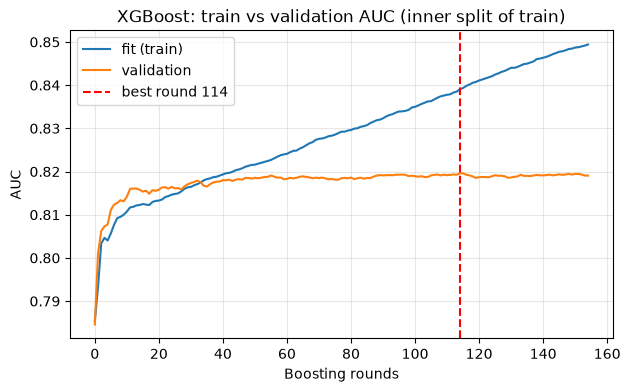

In [11]:
X_fit, X_val, y_fit, y_val = train_test_split(X_tr, y_tr, test_size=0.2, stratify=y_tr, random_state=1)

xgb_es = XGBClassifier(
    n_estimators=1000, learning_rate=0.05, max_depth=3, min_child_weight=5,
    subsample=0.8, colsample_bytree=0.8, scale_pos_weight=pos_weight,
    eval_metric='auc', early_stopping_rounds=40, tree_method='hist', n_jobs=-1, random_state=42)
xgb_es.fit(X_fit, y_fit, eval_set=[(X_fit, y_fit), (X_val, y_val)], verbose=False)

hist = xgb_es.evals_result()
plt.figure(figsize=(7, 4))
plt.plot(hist['validation_0']['auc'], label='fit (train)')
plt.plot(hist['validation_1']['auc'], label='validation')
plt.axvline(xgb_es.best_iteration, color='red', linestyle='--', label=f'best round {xgb_es.best_iteration}')
plt.xlabel('Boosting rounds')
plt.ylabel('AUC')
plt.title('XGBoost: train vs validation AUC (inner split of train)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Train AUC badhta hi rehta hai, lekin validation ek jagah ruk jaata hai. Wo mod hi overfitting ki shuruaat hai. Ye validation split bhi X_train ka hissa hai, test ka nahi. Ek hi split se aaya best_iteration shorki hota hai, to ise sirf ek hint maano, kal ke GridSearchCV mein n_estimators ka range tay karne ke liye. (Agar tumhara xgboost purana hai aur early_stopping_rounds constructor mein error de, to use fit(...) ke andar pass karo.)

7. Feature importance ka sahi tareeka (permutation, validation par):

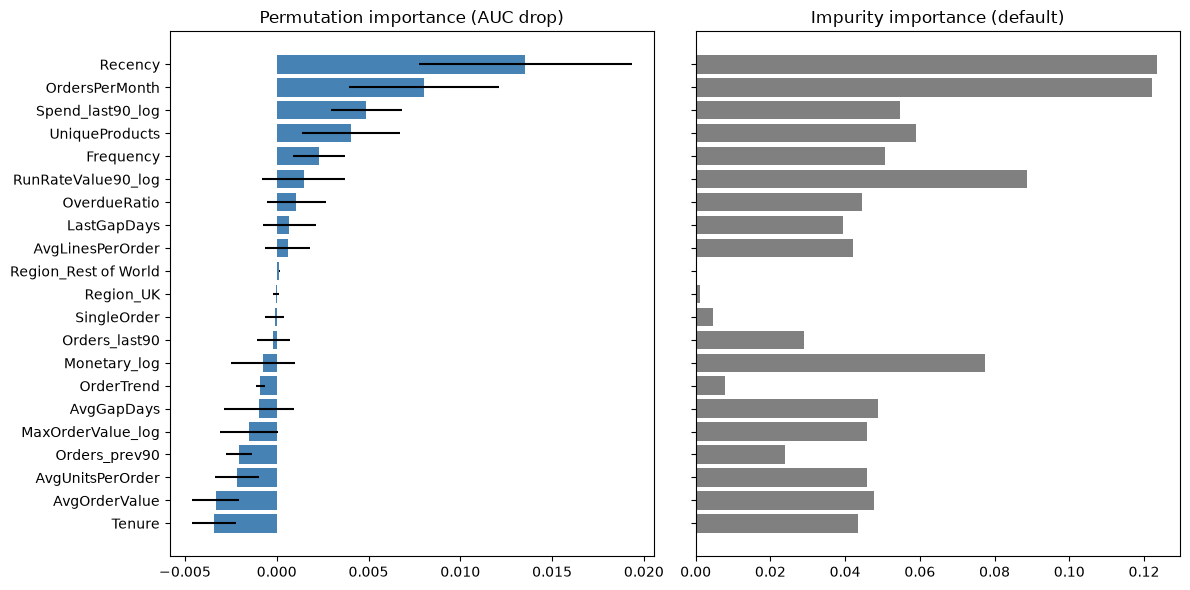

In [14]:
from sklearn.inspection import permutation_importance

rf = clone(models['RandomForest']).fit(X_fit, y_fit)
pi = permutation_importance(rf, X_val, y_val, scoring='roc_auc', n_repeats=20, random_state=0, n_jobs=-1)

imp = pd.DataFrame({'permutation': pi.importances_mean, 'std': pi.importances_std,
                    'impurity': rf.feature_importances_}, index=X_tr.columns).sort_values('permutation')

fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
axes[0].barh(imp.index, imp['permutation'], xerr=imp['std'], color='steelblue')
axes[0].set_title('Permutation importance (AUC drop)')
axes[1].barh(imp.index, imp['impurity'], color='gray')
axes[1].set_title('Impurity importance (default)')
plt.tight_layout()
plt.savefig('../../reports/rf_importance_day83.png', dpi=150)
plt.show()

Kaise padho:

- Default impurity importance continuous features (jaise Monetary_log) ko zyada number deti hai. Permutation importance “is feature ko shuffle karne par score kitna girta hai” naapti hai, to zyada imandaar hai.
- Correlated features (jaise Frequency aur Orders_last90) apni importance aapas mein baant lete hain, aur dono kamzor dikh sakte hain. Isliye isse “yeh feature bekar hai” mat bolo.
- Red flag check: agar ek akela feature ko shuffle karne se AUC 0.2+ gir jaaye, to ruko aur Day 82 ka invariance test dobara chalao. Itni bhari-bharkam dependency aksar leakage ka signal hoti hai.
- Kya top features business sense banate hain (jaise OverdueRatio, Recency, Orders_last90)? SHAP se Day 85B mein is par aur gehra jaayenge.

8. Results save karo (Day 85 ke comparison report mein reuse hoga):

In [15]:
cv_tbl.round(4).to_csv('../../reports/cv_ensembles_day83.csv')
fold_auc.round(4).to_csv('../../reports/cv_folds_auc_day83.csv', index=False)
rep_tbl.round(4).to_csv('../../reports/cv_repeated_day83.csv')

Models abhi save mat karo. Tuned versions kal ban kar final comparison ke baad save honge.

9. Test set ke baare mein ek imandaar baat: Test set par Day 67, 70 aur 71-75 mein LogReg aur Tree score ho chuke hain. Usse kuch tune nahi hua, lekin ab wo “poori tarah kora” nahi hai. Aaj ensembles ko uspar mat chalao. Sahi tareeka: kal tak CV se final model chuno, usse likh kar note kar lo (pre-register), aur Day 85 mein test par sirf wahi model ek baar score karo.

10. Ek honest expectation: Tumhara dataset chhota hai (kuch hazaar customers) aur churn ka signal noisy hai. Aise data par ensemble aksar LogReg se thoda hi behtar hota hai, aur kabhi kabhi barabar. Agar faida chhota ya noise jaisa dikhe, to wo bhi valid finding hai. README mein likho aur simple model rakho. Zyada complex model chun lena sirf isliye ki wo “advanced” hai, interviewer ko achha nahi lagta.

README ke liye note:

## Ensemble Models (Month 5)
Random Forest and XGBoost compared against LogReg and a tuned Decision Tree on the v2 feature set,
using identical 5-fold stratified CV (and 3x repeated CV for the top models).
CV ROC-AUC: LogReg [X], RF [X], XGBoost [X]. [Faida clear tha / fark noise ke andar tha, apna verdict]

practice questions:

1. RF mein min_samples_leaf=1 aur min_samples_leaf=20 dono chalao. Train AUC aur CV AUC ka gap kaise badalta hai? Wahi Day 69 wala overfitting pattern hai.
2. XGBoost mein learning_rate=0.3 aur 0.02 ke saath early stopping chalao. best_iteration kitna badalta hai? Apne shabdon mein likho ki learning_rate aur n_estimators kaise ek doosre ko balance karte hain.
3. Bagging aur boosting ka fark 4 lines mein likho, jaise ek junior ko samjha rahe ho.